In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# Import required libraries for simulation, data handling, and visualization (This usually takes 40-60 seconds)

# Standard libraries for time handling
import datetime

# Data analysis and numerical computation
import pandas as pd          # structured data (tables, CSVs)
import numpy as np           # numerical operations and arrays

# Plotting and visualization
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse   # used for dispersion ellipses

# RocketPy core simulation classes
from rocketpy import (
    Environment, Flight, Function, MonteCarlo, Rocket,
    SolidMotor, Fluid, CylindricalTank, MassFlowRateBasedTank,
    HybridMotor, GenericMotor
)

# RocketPy stochastic (Monte Carlo variation) components
from rocketpy.stochastic import (
    StochasticEnvironment,
    StochasticFlight,
    StochasticNoseCone,
    StochasticParachute,
    StochasticRailButtons,
    StochasticRocket,
    StochasticSolidMotor,
    StochasticTail,
    StochasticTrapezoidalFins,
    StochasticGenericMotor
)

# Geospatial raster handling (maps, terrain)
import rasterio
from rasterio.windows import from_bounds   # crop map regions

# Coordinate transformations (lat/lon ↔ projected coords)
from pyproj import Transformer

# Custom rocket simulation wrapper/module
from rocket_pams import rocket_sim

from paths import get_cwd

In [3]:
# Creating rocket simulation object
rs = rocket_sim()  
# This comes from our own file and has the rocket setup + functions we use to run simulations

In [4]:
# Path to thrust curve file
thrust_curve = str(get_cwd().parent / "Files" / "Q-8159_columbia-hybrid.rse")
# File that contains thrust vs time data for the motor (used in the simulation)

# Creating motor used for the simulation
deterministic_motor = rs.rocket_motor(thrust_curve)  

/opt/miniconda3/envs/myenv/lib/python3.12/site-packages/rocketpy/motors/motor.py:998: UserWarning: burn_time argument (0, 12.7) is out of thrust source time range. Using thrust_source boundary times instead: (0, 12.335) s.
If you want to change the burn out time of the curve please use the 'reshape_thrust_curve' argument.
  warnings.warn(


#drogue+main

In [5]:
power_off_drag = str(get_cwd().parent / "Files" / "drag_off.csv")
power_on_drag  = str(get_cwd().parent / "Files" / "drag_on.csv")

# Create rocket and its components
deterministic_rocket, rail_buttons, nose, trapezoidal_fins, tail,  main = rs.rocket_body(
    deterministic_motor, power_off_drag, power_on_drag, 'main_only'
)

# We pass in: (motor, drag_off, drag_on, flight_type)

# motor → motor used for the simulation

# power_off_drag → drag when motor is OFF
# (drag coefficient vs Mach when not thrusting)

# power_on_drag → drag when motor is ON
# (drag coefficient vs Mach during burn)

# flight_type → determines which parachutes are added AND what gets returned:

# 'nominal'
# → both drogue and main parachutes are added
# → returns: rocket, components, drogue, main

# 'main_only'
# → only main parachute is added
# → returns: rocket, components, main (NO drogue returned)

# 'drogue_only'
# → only drogue parachute is added
# → returns: rocket, components, drogue (NO main returned)

# 'ballistic'
# → no parachutes are added
# → returns: only rocket and components (NO drogue or main returned)

# Important:
# the number of returned variables depends on flight_type
# → need to unpack accordingly when calling the function

/opt/miniconda3/envs/myenv/lib/python3.12/site-packages/rocketpy/mathutils/function.py:3854: UserWarning: Interpolation method set to 'spline' because the regular_grid method is not supported.
  warnings.warn(


In [6]:

# Running a single (deterministic) flight simulation
# "Deterministic" means everything is fixed (no randomness)
# Same inputs → same exact trajectory every time
# Used as a baseline before adding variability (Monte Carlo)

deterministic_flight = Flight(
    rocket=deterministic_rocket,
    environment=rs.env,
    rail_length=15.2,
    inclination=88,
    heading=210,
)

# rocket → rocket object we just built
# environment → weather + location conditions

# rail_length → launch rail length (meters), affects initial acceleration
# inclination → launch angle from horizontal (88° ≈ almost vertical)
# heading → launch heading angle relative to north given in degrees.

In [7]:
deterministic_flight.x_impact

np.float64(30946.73232606924)

In [8]:
# Extract key motor and rocket parameters (baseline values)

tb_nom = deterministic_motor.burn_out_time
mp_nom = deterministic_motor.propellant_initial_mass
md_nom = deterministic_motor.dry_mass
x_cg = deterministic_motor.center_of_dry_mass_position
Im = deterministic_motor.total_impulse

x_cm_nom = deterministic_rocket.center_of_mass_without_motor

# These are the nominal (baseline) values from the deterministic setup
# We will vary these later to introduce uncertainty in the simulations

In [9]:

# Creating stochastic (randomized) motor based on the nominal one
stochastic_motor = StochasticGenericMotor(
    generic_motor=deterministic_motor,  

    # All parameters are defined as (mean, standard deviation)
    # → values are sampled from a Gaussian (normal) distribution

    # total impulse → (Im, 5% of Im)
    # 5% (1σ) spread represents realistic variability in motor performance
    total_impulse=(Im, 0.05 * Im),

    # burn start → (0 s, 0.02 s)
    # ignition timing jitter from electronics/igniter delays (1σ = 0.02 s)
    burn_start_time=(0.0, 0.02),

    # burn out time → (tb_nom, 0.05 s)
    # variation in burn duration due to combustion/regression differences
    burn_out_time=(tb_nom, 0.05),

    # propellant mass → (mp_nom, 3% of mp_nom)
    # accounts for casting tolerances and leftover/unburned propellant
    propellant_initial_mass=(mp_nom, 0.03 * mp_nom),

    # dry mass → (md_nom, 2% of md_nom)
    # reflects uncertainty in hardware/assembly mass
    dry_mass=(md_nom, 0.02 * md_nom),

    # center of dry mass → (x_cg, 0.002 m)
    # ~2 mm (1σ) uncertainty in internal mass placement
    center_of_dry_mass_position=(x_cg, 0.002)
)


# Create stochastic rocket (adds uncertainty to aerodynamic + mass properties)
stochastic_rocket = StochasticRocket(
    rocket=deterministic_rocket,

    # drag factors are multipliers: (mean=1, std deviation)
    # → scales the nominal drag curve

    # power-off drag → 10% (1σ)
    # aerodynamic uncertainty is one of the main drivers of landing spread
    power_off_drag_factor=(1.0, 0.10),

    # power-on drag → 15% (1σ)
    # higher uncertainty during burn due to flow complexity
    power_on_drag_factor=(1.0, 0.15),

    # center of mass → (x_cm_nom, 0.003 m)
    # ~3 mm (1σ) shift from integration/assembly tolerances
    center_of_mass_without_motor=(x_cm_nom, 0.003)
)


# Component-level uncertainties (also Gaussian, defined by std dev)

stochastic_rb = StochasticRailButtons(
    rail_buttons=rail_buttons,
    buttons_distance=0.001  # 1 mm (1σ) placement uncertainty
)

stochastic_nosecone = StochasticNoseCone(nosecone=nose)
# includes geometry/mass uncertainty handled internally

stochastic_t_fins = StochasticTrapezoidalFins(trapezoidal_fins=trapezoidal_fins)
# includes fin geometry + alignment uncertainty

stochastic_tails = StochasticTail(tail=tail)
# includes tail geometry uncertainty


# Overall idea:
# each run samples from these Gaussian distributions (1σ = values above)
# → produces slightly different trajectories → gives landing dispersion


In [10]:

stochastic_motor = StochasticGenericMotor(
    generic_motor=deterministic_motor,  # Nominal GenericMotor used as the baseline for Monte Carlo

    # Total impulse uncertainty:
    # Modeled as a Gaussian distribution with 5% (1σ) standard deviation.
    # This captures variability in propellant mass, combustion efficiency,
    # and manufacturing tolerances typical of student-built motors.
    total_impulse=(Im, 0.05 * Im),

    # Burn start time uncertainty:
    # Models ignition timing jitter due to igniter and electrical delays.
    # Mean ignition time is 0 s, with a 1σ uncertainty of 0.02 s.
    burn_start_time=(0.0, 0.02),

    # Burn out time uncertainty:
    # Captures small variations in burn duration caused by regression rate
    # differences and chamber pressure variability.
    burn_out_time=(tb_nom, 0.05),

    # Propellant mass uncertainty:
    # Accounts for casting tolerances, voids, and residual propellant.
    # Modeled as a 3% (1σ) Gaussian uncertainty.
    propellant_initial_mass=(mp_nom, 0.03 * mp_nom),

    # Dry mass uncertainty:
    # Captures manufacturing and assembly tolerances in the motor hardware.
    # Modeled as a 2% (1σ) Gaussian uncertainty.
    dry_mass=(md_nom, 0.02 * md_nom),

    # Center of dry mass position uncertainty:
    # Represents uncertainty in internal component placement and measurement
    # ±2 mm (1σ) is typical for student-built hardware.
    center_of_dry_mass_position=(x_cg, 0.002)
)




stochastic_rocket = StochasticRocket(
    rocket=deterministic_rocket,

    # Aerodynamic uncertainty (dominant source of dispersion)
    power_off_drag_factor=(1.0, 0.10),  # 10% (1σ)
    power_on_drag_factor=(1.0, 0.15),   # 15% (1σ)
 
    # Structural / integration uncertainty
    center_of_mass_without_motor=(x_cm_nom, 0.003)
)

stochastic_rb=StochasticRailButtons(rail_buttons=rail_buttons,buttons_distance=0.001)
stochastic_nosecone=StochasticNoseCone(nosecone=nose)
stochastic_t_fins=StochasticTrapezoidalFins(trapezoidal_fins=trapezoidal_fins)
stochastic_tails=StochasticTail(tail=tail)





In [11]:
# Adding uncertainty to parachute behavior
# (depends on flight_type → only include parachutes that exist)

# In this case: 'main_only'
# → no drogue parachute is created
# → only main parachute is used (triggered at apogee)

stochastic_main = StochasticParachute(
    parachute=main,

    # cd_s → (mean, std dev)
    # 10% (1σ) uncertainty in Cd*S (drag area)
    # captures variability in inflation and deployment behavior
    cd_s=(rs.cd_s_main, 0.1 * rs.cd_s_main),

    # lag → (mean, std dev)
    # delay between trigger and full deployment
    # 1 s nominal with 0.2 s (1σ)
    lag=(1.0, 0.2)
)

# Note:
# drogue is not included here because flight_type = 'main_only'
# → main deploys at apogee and controls descent

# cd_s and lag are sampled from Gaussian distributions
# → affects descent rate and landing location

In [12]:
# Attaching all stochastic components to the rocket

stochastic_rocket.add_motor(stochastic_motor)
# adds the motor with its uncertainty distributions

stochastic_rocket.add_nose(stochastic_nosecone)
# includes nose geometry/mass uncertainty

stochastic_rocket.add_trapezoidal_fins(stochastic_t_fins)
# includes fin geometry/alignment uncertainty

stochastic_rocket.add_tail(stochastic_tails)
# includes tail section uncertainty

stochastic_rocket.set_rail_buttons(
    stochastic_rb, lower_button_position=(0.001, "normal")
)
# sets rail button positions with uncertainty
# lower_button_position → reference position along the rocket

stochastic_rocket.add_parachute(stochastic_main)
# adds both parachutes with CdS + lag uncertainty


# At this point:
# the rocket is fully defined with all uncertainties included
# → ready for Monte Carlo simulations

In [13]:
# Create stochastic flight (adds uncertainty to flight conditions)

stochastic_flight = StochasticFlight(
    flight=deterministic_flight,

    # inclination → (mean, std dev)
    # varies launch angle around 88° with 0.1° (1σ)
    inclination=(88, 0.1)
)

In [14]:
# Creating stochastic environment (adds uncertainty to wind conditions)

stochastic_env = StochasticEnvironment(
    environment=rs.env,

    # wind factors → (mean, std dev)
    # scales the wind profile in x and y directions

    # wind_velocity_x_factor → varies wind in x-direction
    # 25% (1σ) uncertainty → captures forecast error in wind speed
    wind_velocity_x_factor=(1.0, 0.25),

    # wind_velocity_y_factor → varies wind in y-direction
    # same 25% (1σ) uncertainty
    wind_velocity_y_factor=(1.0, 0.25),
)

In [15]:
# Defining function to compute longitudinal moment from flight data

def longitudinal_moment(flight):
    M_pitch = flight.M2[:, 1]  # pitch moment over time
    M_yaw   = flight.M3[:, 1]  # yaw moment over time

    # combining pitch and yaw moments (vector magnitude) and take max value
    return np.max(np.sqrt(M_pitch**2 + M_yaw**2))


# Storing custom output to track during Monte Carlo
custom_data_collector = {
    "longitudinal_moment": longitudinal_moment,
}
# this lets us save the max combined moment for each simulation run

In [16]:
# Setting up Monte Carlo simulation for landing dispersion

dispersion = MonteCarlo(
    filename="landing_dispersion_main_only",

    # stochastic inputs (all include uncertainty distributions)
    environment=stochastic_env,
    rocket=stochastic_rocket,
    flight=stochastic_flight,

    # custom outputs to track for each run
    data_collector=custom_data_collector
)

# Monte Carlo → runs many simulations with random samples from the distributions
# each run is slightly different → gives spread in landing locations (dispersion)
# results are saved under the given filename

The following input file was imported: landing_dispersion_main_only.inputs.txt
A total of 20 simulation results were loaded from: landing_dispersion_main_only.outputs.txt
The following error file was imported: landing_dispersion_main_only.errors.txt


/opt/miniconda3/envs/myenv/lib/python3.12/site-packages/rocketpy/simulation/monte_carlo.py:139: UserWarning: This class is still under testing and some attributes may be changed in next versions
  warnings.warn(


In [17]:
# Run Monte Carlo simulations

dispersion.simulate(
    number_of_simulations=20,   # total number of runs (each run samples new random values) aim for like 500-1000

    append=False,               # overwrite previous results (do not add to existing file)

    include_function_data=False,# do not store full time-series (saves memory, only key outputs)

    parallel=True,              # run simulations in parallel
    n_workers=10                # number of CPU workers used
)

# runs 500 different trajectories with sampled uncertainties
# → builds landing dispersion statistics

Starting Monte Carlo analysis
Running Monte Carlo simulation with 10 workers.
Iterations completed: 000020 | Average Time per Iteration: 0.181 s | Estimated time left: 0 s 
Completed 20 iterations. In total, 20 simulations are exported.
Total wall time: 3.6 s       
Results saved to landing_dispersion_main_only.outputs.txt


In [ ]:
# landing_errors = impact_errors("Some name") 

# Reads landing_dispersion_main_only and checks impact velocity. 
# If, for a simulation, it is too high, it will remove that data point
# Returns a dictionary of the removed data points. Key = Parachute Area

In [ ]:
# Takes both dictionaries from shock and landing errors
# Compiles errors into a document "error_analysis.txt"
# Lists reason of failure (If landing, lists speed. If shock, lists shock force + speed)

# compile_errors(landing_errors, shock_errors) # just set shock_errors to an empty dictionary

In [18]:
# Printing summary statistics of Monte Carlo results

dispersion.info()

Monte Carlo Simulation by RocketPy
Data Source:  landing_dispersion_main_only
Number of simulations:  20
Results: 

                Parameter            Mean          Median       Std. Dev.    95% PI Lower    95% PI Upper
--------------------------------------------------------------------------------------------------------------
 initial_stability_margin           2.190           2.171           0.083           2.040           2.337
     frontal_surface_wind           0.000           0.000           0.000           0.000           0.000
                 x_impact       30072.420       29837.371        9869.899       12497.758       46414.123
         out_of_rail_time           0.688           0.682           0.027           0.649           0.744
          max_mach_number           2.361           2.367           0.157           2.055           2.609
out_of_rail_stability_margin           2.367           2.350           0.080           2.221           2.508
                  t_final   

In [19]:
# Setingt output filename (Monte Carlo automatically appends .outputs.txt)
filename = "landing_dispersion_main_only.outputs.txt"
# results will always be stored as: <filename>.outputs.txt
'''
from earlier
dispersion = MonteCarlo(
    filename="<filename>",


    environment=stochastic_env,
    rocket=stochastic_rocket,
    flight=stochastic_flight,

    data_collector=custom_data_collector
)
'''

# Initializing storage for results
dispersion_general_results = []
# list of full dictionaries (one per simulation)

dispersion_results = {
    "out_of_rail_time": [],
    "out_of_rail_velocity": [],
    "apogee_time": [],
    "apogee_altitude": [],
    "apogee_x": [],
    "apogee_y": [],
    "impact_time": [],
    "x_impact": [],
    "y_impact": [],
    "impact_velocity": [],
    "initial_static_margin": [],
    "out_of_rail_static_margin": [],
    "final_static_margin": [],
    "number_of_events": [],
    "max_velocity": [],
    "drogue_triggerTime": [],
    "drogue_inflated_time": [],
    "drogue_inflated_velocity": [],
    "execution_time": [],
    "longitudinal_moment": [],
}
# dictionary of lists → each key stores values across all simulations


# Open Monte Carlo output file
dispersion_output_file = open(str(filename), "r+")
# file contains one dictionary per simulation (one per line)


# Read file line by line
for line in dispersion_output_file:

    # skip lines that are not data (comments / headers)
    if line[0] != "{":
        continue

    # convert string → dictionary
    flight_result = eval(line)

    # store full result
    dispersion_general_results.append(flight_result)

    # extract each parameter into its own list
    for parameter_key in dispersion_results.keys():
        if parameter_key in flight_result:
            dispersion_results[parameter_key].append(flight_result[parameter_key])


# Close file after reading
dispersion_output_file.close()


# Total number of simulations loaded
N = len(dispersion_general_results)
print("Number of simulations: ", N)


# At this point:
# dispersion_general_results → full data per run
# dispersion_results → easy access to each variable across all runs

Number of simulations:  20


In [20]:
label = "Main"  # label for this case (recovery configuration)

# Get longitudinal moment values from Monte Carlo
loads = np.array(dispersion_results["longitudinal_moment"])  # convert list → array for calculations

# Mean and standard deviation of the distribution
mean = np.mean(loads)  # average longitudinal moment
std  = np.std(loads)   # spread of the values (1σ)

# Identify values within 2σ of the mean
inside_2sigma = np.abs(loads - mean) <= 2 * std  # keeps values within mean ± 2σ

loads_2sigma = loads[inside_2sigma]  # filtered data (removes extreme outliers)

# Maximum longitudinal moment within 2σ range
largest_within_2sigma = np.max(loads_2sigma)  # representative worst-case load

print(f"--- {label} ---")
print(f"Largest longitudinal moment inside 2σ: {largest_within_2sigma:,.1f} N·m")


'''Longitudinal moment was asked about in the progress report 
and refers to the combined pitch and yaw moment acting on the rocket, 
representing the torque that tries to rotate it away from its flight direction'''

--- Main ---
Largest longitudinal moment inside 2σ: 175.3 N·m


'Longitudinal moment was asked about in the progress report \nand refers to the combined pitch and yaw moment acting on the rocket, \nrepresenting the torque that tries to rotate it away from its flight direction'

In [21]:
# Monte Carlo impacts (landing positions)
impact_x = np.array(dispersion_results["x_impact"])
impact_y = np.array(dispersion_results["y_impact"])
# arrays of landing coordinates from all simulations

# Deterministic impact (single baseline trajectory)
det_x = deterministic_flight.x_impact
det_y = deterministic_flight.y_impact

# Creating DataFrame for Monte Carlo results
df_mc = pd.DataFrame({
    "type": "monte_carlo",
    "impact_x_m": impact_x,
    "impact_y_m": impact_y
})

# Creating DataFrame for deterministic result
df_det = pd.DataFrame({
    "type": ["deterministic"],
    "impact_x_m": [det_x],
    "impact_y_m": [det_y]
})

# Combining both into one dataset
df_all = pd.concat([df_mc, df_det], ignore_index=True)

# Saving to CSV file
df_all.to_csv("landing_dispersion_main_only.csv", index=False)
# stores x and y impact points → used later to plot landing dispersion

print("Saved to landing_dispersion_main_only.csv")

Saved to landing_dispersion_main_only.csv


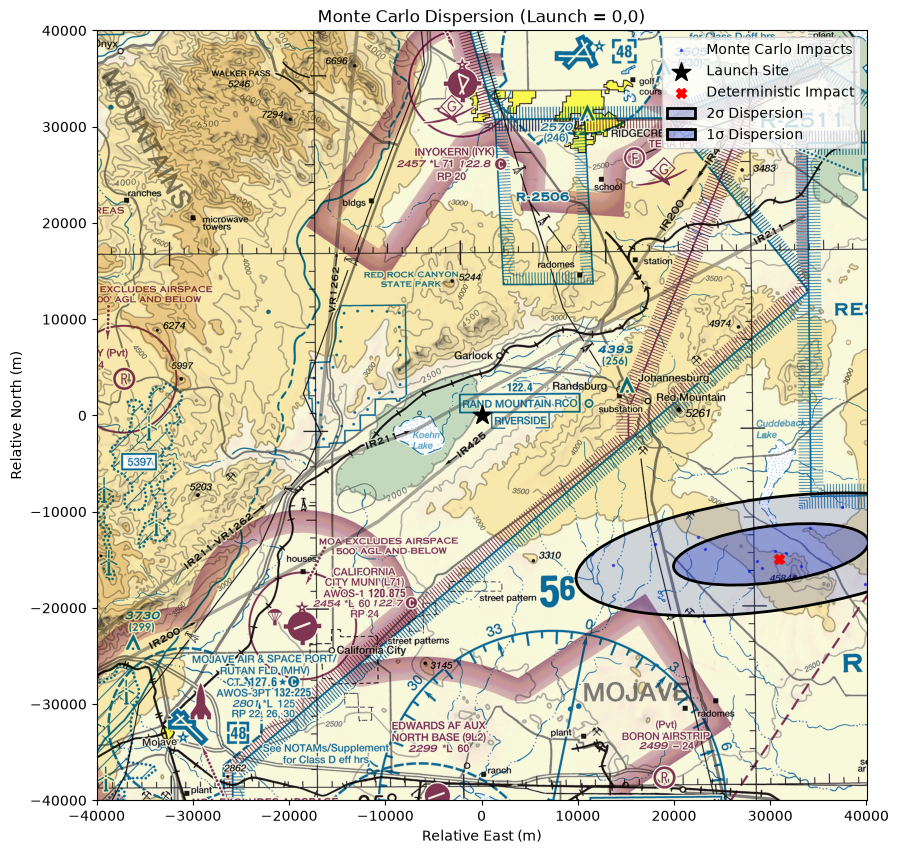

In [22]:
# ============================================
# SECTIONAL MAP + MONTE CARLO
# Axes in meters, Launch = (0,0)
# 1σ and 2σ ellipses
# ============================================

sectional_path = "Los Angeles SEC.tif"  # sectional map file is specified

fig, ax = plt.subplots(figsize=(10,10))  # square plotting area is created

with rasterio.open(sectional_path) as src:

    # Launch coordinates are converted from lat/lon to projected meters
    transformer = Transformer.from_crs("EPSG:4326", src.crs, always_xy=True)
    launch_x_abs, launch_y_abs = transformer.transform(rs.long, rs.lat)

    buffer = 40000  # a 40 km window around launch is defined

    # Bounds of the map region are set around the launch location
    min_x = launch_x_abs - buffer
    max_x = launch_x_abs + buffer
    min_y = launch_y_abs - buffer
    max_y = launch_y_abs + buffer

    # Raster is cropped to the region of interest
    window = from_bounds(min_x, min_y, max_x, max_y, src.transform)

    band = src.read(1, window=window)     # raster data is read
    colormap = src.colormap(1)            # color mapping is retrieved
    transform = src.window_transform(window)  # spatial transform is obtained


# Indexed raster values are converted to RGB image
rgb = np.zeros((band.shape[0], band.shape[1], 3), dtype=np.uint8)

for key, value in colormap.items():
    rgb[band == key] = value[:3]  # RGB values are assigned


# Absolute map extent is computed in projected coordinates
left = transform.c
top = transform.f
right = left + transform.a * band.shape[1]
bottom = top + transform.e * band.shape[0]
extent_abs = [left, right, bottom, top]


# Coordinates are shifted so that launch is at (0,0)
extent_rel = [
    extent_abs[0] - launch_x_abs,
    extent_abs[1] - launch_x_abs,
    extent_abs[2] - launch_y_abs,
    extent_abs[3] - launch_y_abs
]


# Sectional map is plotted
ax.imshow(rgb, extent=extent_rel)


# ============================================
# Monte Carlo (relative coordinates)
# ============================================

# Landing positions from Monte Carlo are extracted
impact_x_rel = np.array(dispersion_results["x_impact"])
impact_y_rel = np.array(dispersion_results["y_impact"])

# Launch is defined as the origin
launch_x = 0
launch_y = 0


# All impact points are plotted
ax.scatter(
    impact_x_rel,
    impact_y_rel,
    s=2,
    color="blue",
    alpha=0.6,
    label="Monte Carlo Impacts"
)

# Launch location is plotted
ax.scatter(
    launch_x,
    launch_y,
    s=200,
    marker="*",
    color="black",
    zorder=5,
    label="Launch Site"
)
# Deterministic landing
det_x_rel = deterministic_flight.x_impact
det_y_rel = deterministic_flight.y_impact

# Deterministic landing point is plotted
ax.scatter(
    det_x_rel, det_y_rel,
    s=50,
    marker="X",
    color="red",
    label="Deterministic Impact",
    zorder=5
)


# ============================================
# Covariance & Eigenvalues
# ============================================

# Covariance matrix of impact positions is computed
cov = np.cov(impact_x_rel, impact_y_rel)

# Eigenvalues and eigenvectors are computed
vals, vecs = np.linalg.eigh(cov)

# Eigenvalues are sorted (largest first)
order = vals.argsort()[::-1]
vals = vals[order]
vecs = vecs[:, order]

# Rotation angle of ellipse is computed
theta = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))

# Center of dispersion is computed
center_x = impact_x_rel.mean()
center_y = impact_y_rel.mean()


# ============================================
# 1σ Ellipse
# ============================================

# 1σ ellipse is created using covariance
ellipse_1 = Ellipse(
    (center_x, center_y),
    2 * np.sqrt(vals[0]),   # width = 2 * 1σ
    2 * np.sqrt(vals[1]),   # height = 2 * 1σ
    angle=theta,
    facecolor=(0.1, 0.2, 0.8, 0.35),
    edgecolor="black",
    linewidth=2,
    label="1σ Dispersion"
)


# ============================================
# 2σ Ellipse
# ============================================

# 2σ ellipse is created using scaled covariance
ellipse_2 = Ellipse(
    (center_x, center_y),
    4 * np.sqrt(vals[0]),   # width = 2 * 2σ
    4 * np.sqrt(vals[1]),   # height = 2 * 2σ
    angle=theta,
    facecolor=(0.1, 0.2, 0.8, 0.18),
    edgecolor="black",
    linewidth=2,
    label="2σ Dispersion"
)

# Larger ellipse is drawn first
ax.add_patch(ellipse_2)

# Smaller ellipse is drawn on top
ax.add_patch(ellipse_1)


# ============================================
# Final Formatting
# ============================================

# Plot limits are set to match map extent
ax.set_xlim(extent_rel[0], extent_rel[1])
ax.set_ylim(extent_rel[2], extent_rel[3])

# Aspect ratio is enforced to keep distances correct
ax.set_aspect("equal")

# Axis labels and title are set
ax.set_xlabel("Relative East (m)")
ax.set_ylabel("Relative North (m)")
ax.set_title("Monte Carlo Dispersion (Launch = 0,0)")

# Legend is displayed
ax.legend()

# Plot is shown
plt.show()